In [ ]:

# EAST AFRICA FINANCIAL INCLUSION ANALYSIS

Analyst: Ismaila Ainoko Aminu

Dataset: East Africa Financial Inclusion Survey

## 1. Project Overview

Financial inclusion plays an important role in economic development by providing individuals with access to essential financial services such as savings, payments, credit, and formal banking facilities.

Despite improvements in financial technology and banking services across Africa, a significant number of individuals still face challenges accessing formal financial services.

This project explores financial inclusion patterns across East Africa by analysing demographic, socioeconomic, and geographic factors that may influence access to formal financial accounts.

## 2. Business Problem

Financial institutions and policy makers need reliable information to understand the factors contributing to financial exclusion.

Without adequate data analysis, it becomes difficult to identify underserved populations, understand barriers to financial access, and develop effective strategies to improve financial inclusion.

## 3. Business Objective

To analyse financial inclusion patterns across East Africa, identify demographic and socioeconomic factors associated with formal financial account ownership, and generate actionable insights that can support financial institutions and policymakers in improving access to financial services.

## 4. Key Business Questions

1. What percentage of individuals have access to formal financial accounts?
2. Which countries have the highest and lowest financial inclusion rates?
3. Is there a relationship between gender and financial account ownership?
4. How does age influence access to formal financial services?
5. Does education level affect financial inclusion?
6. How does employment status relate to financial account ownership?
7. Which demographic groups are most financially excluded?

## 5. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## 6. Expected Outcome

The analysis aims to uncover patterns of financial inclusion and exclusion, identify underserved demographic groups, and provide evidence-based recommendations that can help improve financial access across the selected East African countries.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 3. Loading the Dataset

## The dataset will be imported into a Pandas DataFrame to enable inspection, cleaning, and exploratory data analysis.


In [3]:
df = pd.read_csv('East_Africa_Financial_Inclusion_Survey.csv')

df.head()   #This display the first fove rows in my dataset 

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [4]:
df.describe()    # Checking statistical summary of my dataset

,year,household_size,age_of_respondent
count,23524.000000,23524.000000,23524.000000
mean,2016.975939,3.797483,38.805220
std,0.847371,2.227613,16.520569
min,2016.000000,1.000000,16.000000
25%,2016.000000,2.000000,26.000000
50%,2017.000000,3.000000,35.000000
75%,2018.000000,5.000000,49.000000
max,2018.000000,21.000000,100.000000


In [11]:
df.columns # To understand the meaning of my column 

Index(['country', 'year', 'uniqueid', 'bank_account', 'location_type',
       'cellphone_access', 'household_size', 'age_of_respondent',
       'gender_of_respondent', 'relationship_with_head', 'marital_status',
       'education_level', 'job_type'],
      dtype='object')

In [12]:
df.dtypes  # To know the data type of my column

country                   object
year                       int64
uniqueid                  object
bank_account              object
location_type             object
cellphone_access          object
household_size             int64
age_of_respondent          int64
gender_of_respondent      object
relationship_with_head    object
marital_status            object
education_level           object
job_type                  object
dtype: object

In [17]:
df.shape  # My dataset has 13 column ans 23,524 rows 

(23524, 13)

In [18]:
df.isnull().sum()   # checking if there is missing value 

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)


##  Exploratory Data Analysis (EDA)

#### Exploratory Data Analysis (EDA) involves examining and summarising data to understand patterns, relationships, distributions, and trends.

#### In this project, EDA will help uncover factors associated with financial inclusion across East Africa.

#### The analysis will focus on demographic characteristics, geographic differences, socioeconomic factors, and bank account ownership.


####  Calculate the overall percentage of respondents who own a bank account by country 

In [21]:
# Calculate the overall percentage of respondents who own a bank account
bank_account = df['bank_account'].value_counts(normalize=True) *100
print('Overall Bank Account Access:')
print(bank_account)

Overall Bank Account Access:
bank_account
No     85.920762
Yes    14.079238
Name: proportion, dtype: float64


In [22]:
## Overall percentage of respondent who own a bank account by country

country_bank_account = df.groupby('country')['bank_account'].value_counts(normalize=True) * 100

print('Bank Account Access by Country:')
print(country_bank_account)

Bank Account Access by Country:
country   bank_account
Kenya     No              74.934080
          Yes             25.065920
Rwanda    No              88.517459
          Yes             11.482541
Tanzania  No              90.830816
          Yes              9.169184
Uganda    No              91.385055
          Yes              8.614945
Name: proportion, dtype: float64


##  Business Question 2: Investigate Geographic & Technological Gaps (Location & Cellphone Access

In [5]:
# Do people living in rural areas have lower bank-account ownership than people living in urban areas?

location_bank_account = (
    df.groupby('location_type')['bank_account']
    .value_counts(normalize =True) * 100
)

cellphone_bank_access = (
    df.groupby('cellphone_access')['bank_account']
    .value_counts(normalize = True) * 100
)

print(location_bank_account)
print()
print('=== Cell Phone Bank Access ===')
print(cellphone_bank_access)

location_type  bank_account
Rural          No              88.349718
               Yes             11.650282
Urban          No              82.126130
               Yes             17.873870
Name: proportion, dtype: float64

=== Cell Phone Bank Access ===
cellphone_access  bank_account
No                No              98.286656
                  Yes              1.713344
Yes               No              81.620259
                  Yes             18.379741
Name: proportion, dtype: float64


## Business Question 3: Analyze Socioeconomic & Demographic Drivers (Education, Job Type, & Gender)

In [24]:
education_bank_level = (
    df.groupby('education_level')['bank_account']
    .value_counts(normalize = True) * 100
)

job_bank_type = (
    df.groupby('job_type')['bank_account']
    .value_counts(normalize = True) * 100
)

gender_bank_account = (
    df.groupby('gender_of_respondent')['bank_account']
    .value_counts(normalize = True) * 100
)

print('Bank Account Ownershp By Education Level:')
print(education_bank_level)
print()
print('Bank Account Ownershp By Job Type:')
print(job_bank_type)
print()
print('Bank Account Ownershp By Gender:')
print(gender_bank_account)

Bank Account Ownershp By Education Level:
education_level                  bank_account
No formal education              No              96.101883
                                 Yes              3.898117
Other/Dont know/RTA              No              68.571429
                                 Yes             31.428571
Primary education                No              91.454929
                                 Yes              8.545071
Secondary education              No              76.722709
                                 Yes             23.277291
Tertiary education               Yes             51.080380
                                 No              48.919620
Vocational/Specialised training  Yes             57.036115
                                 No              42.963885
Name: proportion, dtype: float64

Bank Account Ownershp By Job Type:
job_type                      bank_account
Dont Know/Refuse to answer    No              88.888889
                              Yes   

## Step 4: Age Distribution Analysis

In [25]:
df['age_of_respondent'].describe()

count    23524.000000
mean        38.805220
std         16.520569
min         16.000000
25%         26.000000
50%         35.000000
75%         49.000000
max        100.000000
Name: age_of_respondent, dtype: float64

In [26]:
df['age_group'] = pd.cut(df['age_of_respondent'], 
                         bins=[15, 25, 35, 50, 100], 
                         labels=['Youth (16-25)', 'Young Adult (26-35)', 'Adult (36-50)', 'Senior (51+)'])
age_inclusion = pd.crosstab(df['age_group'], 
                            df['bank_account'], normalize='index') * 100
print("Bank Account Access by Age Group (%):\n", age_inclusion)

Bank Account Access by Age Group (%):
 bank_account                No        Yes
age_group                                
Youth (16-25)        91.501518   8.498482
Young Adult (26-35)  83.188803  16.811197
Adult (36-50)        82.625929  17.374071
Senior (51+)         87.176582  12.823418


## Visualizations & Storytelling (Matplotlib & Seaborn)

###  Overall Bank Account Access in East Africa

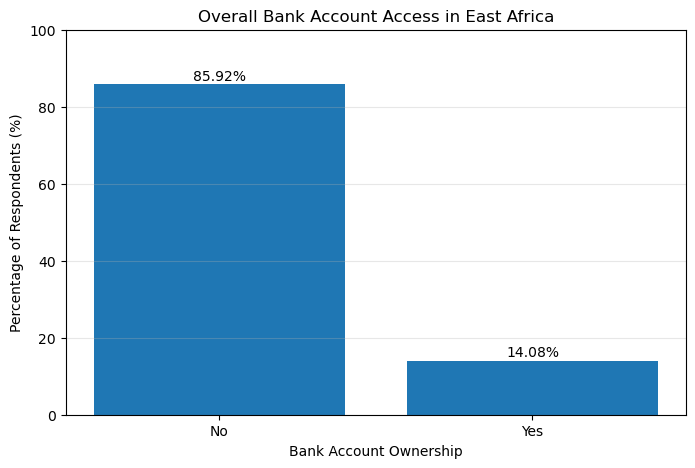

In [27]:
# Key Findings

# The analysis reveals that 85.92% of respondents do not own a formal bank account, while only 14.08% have access to one.

# This indicates a substantial financial inclusion gap among the respondents surveyed.

### Business Implication

# Financial institutions and policymakers should investigate the barriers preventing individuals from accessing formal banking services and develop targeted strategies to improve financial inclusion.


plt.figure(figsize=(8, 5))

plt.bar(bank_account.index, 
        bank_account.values
)

plt.title('Overall Bank Account Access in East Africa')
plt.xlabel('Bank Account Ownership')
plt.ylabel('Percentage of Respondents (%)')

plt.ylim(0, 100)

for i, value in enumerate(bank_account.values):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.grid(axis='y', alpha=0.3)

plt.show()
    

### Bank Account Ownership by residential Location

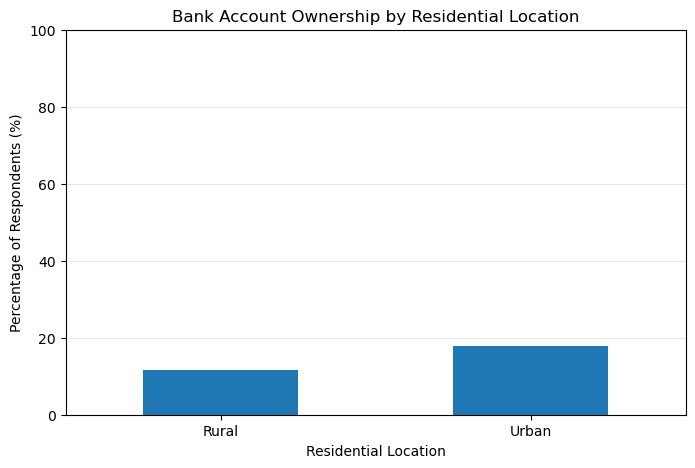

In [28]:
plt.figure(figsize=(8, 5))

location_bank_account.xs('Yes', level='bank_account').plot(kind='bar')

plt.title('Bank Account Ownership by Residential Location')
plt.xlabel('Residential Location')
plt.ylabel('Percentage of Respondents (%)')

plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.show()

### Bank Account Ownership By Country

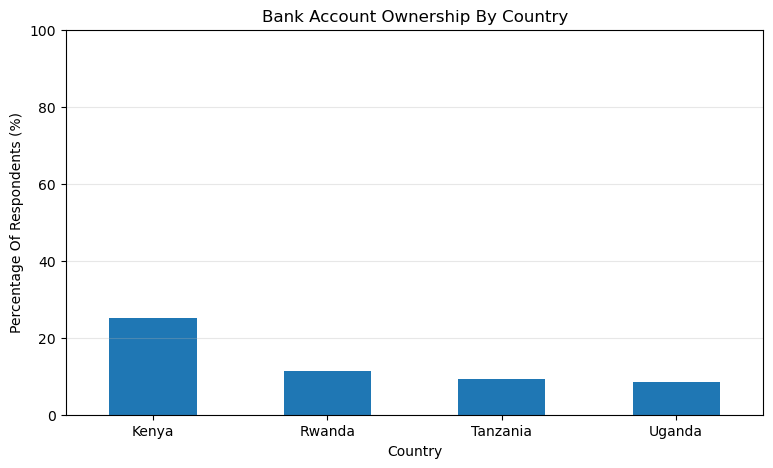

In [33]:
plt.figure(figsize=(9, 5))

country_bank_account.xs('Yes', level='bank_account').plot(kind='bar')
plt.title('Bank Account Ownership By Country')
plt.xlabel('Country')
plt.ylabel('Percentage Of Respondents (%)')

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.show()
           

           

### Bank account ownership by cellphone access.

In [5]:
plt.figure(figsize=(9, 5))

cellphone_bank_access.xs('Yes', level='bank_account').plot(kind='bar')
plt.title('Bank account ownership by cellphone access')
plt.xlabel('Cellphone Access')
plt.ylabel('percentage by respondent (%)')

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.show()


NameError: name 'cellphone_bank_access' is not defined

<Figure size 900x500 with 0 Axes>

### Educational Bank Level

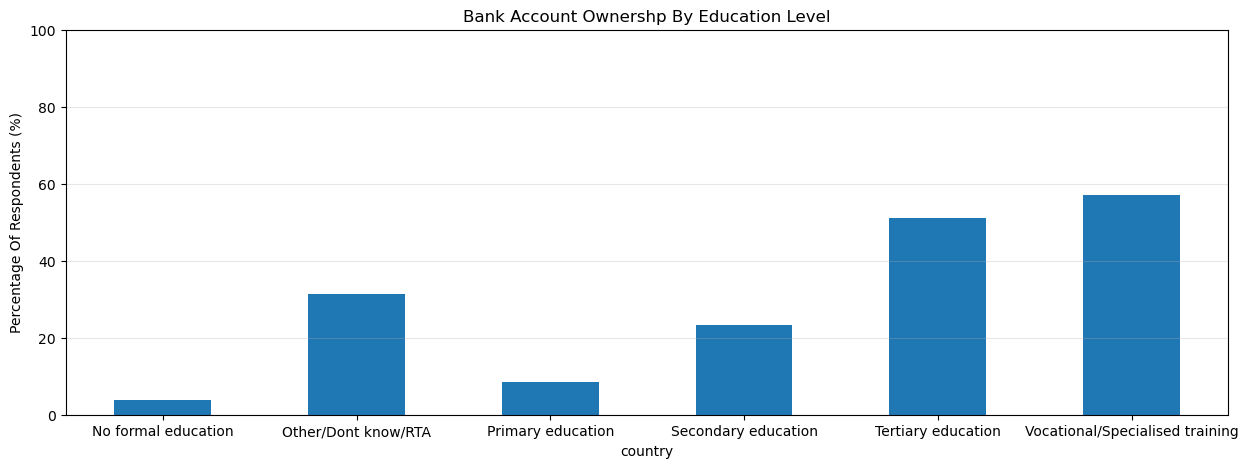

In [48]:
plt.figure(figsize=(15, 5))  

education_bank_level.xs('Yes', level='bank_account').plot(kind='bar')

plt.title('Bank Account Ownershp By Education Level')
plt.xlabel('country')
plt.ylabel('Percentage Of Respondents (%)')

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.show()

###  job_bank_type

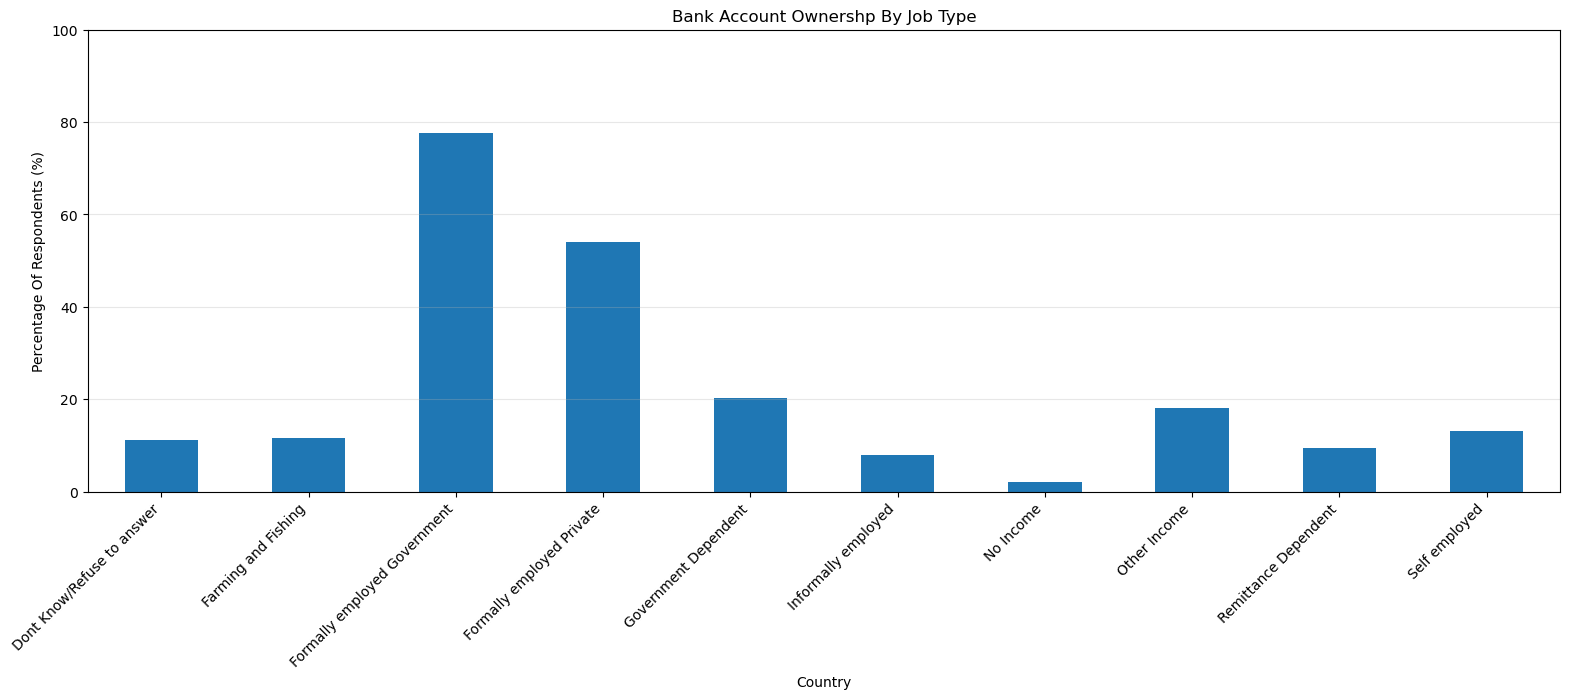

In [64]:
plt.figure(figsize=(19, 6))

job_bank_type.xs('Yes', level='bank_account').plot(kind='bar')

plt.title('Bank Account Ownershp By Job Type')
plt.xlabel('Country')
plt.ylabel('Percentage Of Respondents (%)')

plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.show()


### Gender By Bank Account

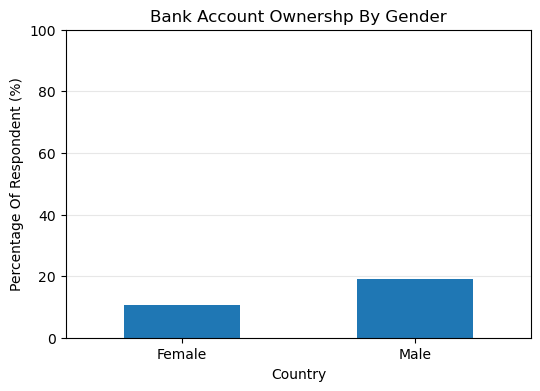

In [68]:
plt.figure(figsize=(6, 4))

gender_bank_account.xs('Yes', level='bank_account').plot(kind='bar')
plt.title('Bank Account Ownershp By Gender')
plt.xlabel('Country')
plt.ylabel('Percentage Of Respondent (%)')

plt.ylim(0, 100)
plt.xticks(rotation=0)

plt.grid(axis='y', alpha=0.3)
plt.show()

### Bank Account Ownership By Age Group

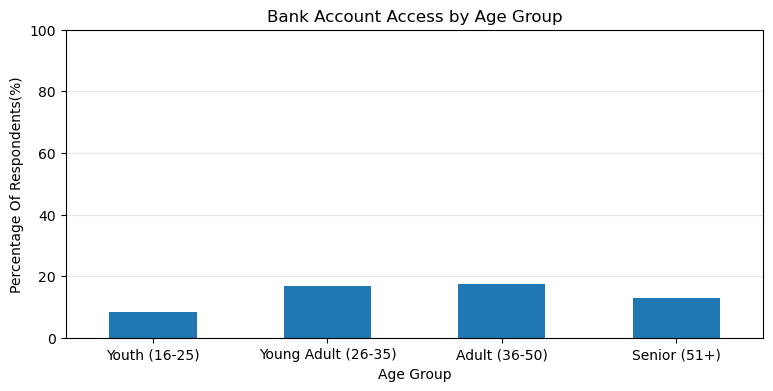

In [80]:
plt.figure(figsize=(9, 4))

age_inclusion['Yes'].plot(kind='bar')

plt.title('Bank Account Access by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Percentage Of Respondents(%)')

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.show()